# Exploratory data analysis

Goals:
- understand each variable: type, domain, distribution, missing values
- feed the fundamental analysis in `00_framing` (What, Who, When, Where, How, Why, red flags);
- study the target and its relationships with the features.

## 1. Setup

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

In [6]:
train = pd.read_csv("../data/train_data.csv")
test = pd.read_csv("../data/test_data.csv")

## 2. Overview

In [8]:
print (f"train data shape: {train.shape}")
print (f"test data shape: {test.shape}")

train data shape: (143579, 14)
test data shape: (21455, 13)


In [5]:
train.head()

,ID,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,37765,15794860,Ch'eng,627,France,Male,28.0,7,131694.04,1,1.0,1.0,161205.61,0
1,130453,15728005,Hargreaves,597,France,Male,34.0,2,0.00,2,0.0,1.0,181419.29,0
2,77297,15686810,Ts'ui,724,France,Male,39.0,7,0.00,2,1.0,1.0,100862.54,0
3,40858,15760244,Trevisano,663,Germany,Female,56.0,5,118577.24,3,1.0,0.0,61164.45,1
4,19804,15810563,French,627,France,Female,33.0,5,0.00,2,1.0,1.0,103737.82,0


In [6]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 143579 entries, 0 to 143578
Data columns (total 14 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   ID               143579 non-null  int64  
 1   CustomerId       143579 non-null  int64  
 2   Surname          143579 non-null  str    
 3   CreditScore      143579 non-null  int64  
 4   Geography        143579 non-null  str    
 5   Gender           143579 non-null  str    
 6   Age              143579 non-null  float64
 7   Tenure           143579 non-null  int64  
 8   Balance          143579 non-null  float64
 9   NumOfProducts    143579 non-null  int64  
 10  HasCrCard        143579 non-null  float64
 11  IsActiveMember   143579 non-null  float64
 12  EstimatedSalary  143579 non-null  float64
 13  Exited           143579 non-null  int64  
dtypes: float64(5), int64(6), str(3)
memory usage: 15.3 MB


In [7]:
summary = pd.DataFrame({
    "dtype": train.dtypes,
    "n_unique": train.nunique(),
    "min": train.min(numeric_only=True),
    "max": train.max(numeric_only=True),
})
summary

,dtype,n_unique,min,max
Age,float64,71,18.00,92.00
Balance,float64,27258,0.00,250898.09
CreditScore,int64,456,350.00,850.00
CustomerId,int64,22017,15565701.00,15815690.00
EstimatedSalary,float64,50076,11.58,199992.48
Exited,int64,2,0.00,1.00
Gender,str,2,NaN,NaN
Geography,str,3,NaN,NaN
HasCrCard,float64,2,0.00,1.00
ID,int64,143579,0.00,165033.00


**Variable types**
- Identifiers (not features): `ID`, `CustomerId`
- Categorical / discrete: `Surname`, `Geography`, `Gender`, `NumOfProducts`, `Tenure`, `HasCrCard`, `IsActiveMember`
- Continuous: `CreditScore`, `Age`, `Balance`, `EstimatedSalary`
- Target: `Exited` (binary)

In [8]:
train.isna().sum()

ID                 0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

No missing values in any column.

## 3. Target

In [9]:
train["Exited"].value_counts(normalize=True)

Exited
0    0.787922
1    0.212078
Name: proportion, dtype: float64

<Axes: xlabel='Exited'>

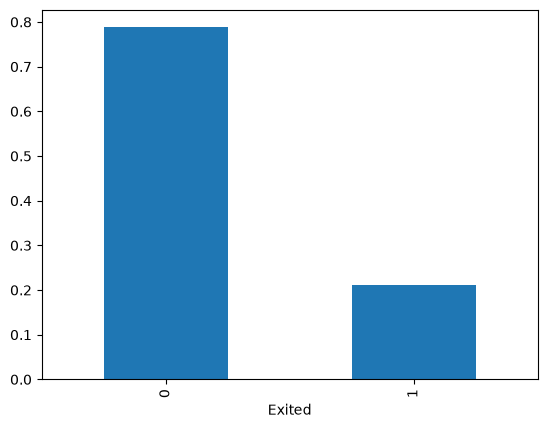

In [10]:
train["Exited"].value_counts(normalize=True).plot(kind="bar")

`Exited` is binary and imbalanced: about 21% churn (1) vs 79% stay (0).

## 4. Data origin

I compare our data with the Kaggle Playground competition [S4E1](https://www.kaggle.com/competitions/playground-series-s4e1/data), whose data is documented as *"generated from a deep learning model trained on the Bank Customer Churn Prediction dataset"*.

In [4]:
import kagglehub

path = kagglehub.competition_download("playground-series-s4e1")
s4e1 = pd.read_csv(path + "/train.csv")

summary_s4e1 = pd.DataFrame({
    "dtype": s4e1.dtypes,
    "n_unique": s4e1.nunique(),
    "min": s4e1.min(numeric_only=True),
    "max": s4e1.max(numeric_only=True),
})
summary_s4e1

Path to competition files: /home/amine/.cache/kagglehub/competitions/playground-series-s4e1


,dtype,n_unique,min,max
Age,float64,71,18.00,92.00
Balance,float64,30075,0.00,250898.09
CreditScore,int64,457,350.00,850.00
CustomerId,int64,23221,15565701.00,15815690.00
EstimatedSalary,float64,55298,11.58,199992.48
Exited,int64,2,0.00,1.00
Gender,str,2,NaN,NaN
Geography,str,3,NaN,NaN
HasCrCard,float64,2,0.00,1.00
IsActiveMember,float64,2,0.00,1.00


**Comparison with our data (section 2):**
- **Row count**: S4E1 train has 165,034 rows (`id` from 0 to 165,033). Our train + test = 143,579 + 21,455 = 165,034, and our `ID` also ranges from 0 to 165,033.
- **Unique values**: S4E1 always has slightly more unique values than our train (`CustomerId` 23,221 vs 22,017, `Surname` 2,797 vs 2,765, `Balance` 30,075 vs 27,258). This is consistent with our train being a subset of S4E1 (a subset cannot have more unique values), but it is not a proof.
- **Types**: same dtypes (e.g. `Age`, `HasCrCard`, `IsActiveMember` stored as float64 in both).
- **Ranges**: identical min and max for every numeric column, to the cent (e.g. `Balance` 0 to 250,898.09, `EstimatedSalary` 11.58 to 199,992.48, `Age` 18 to 92). A subset must stay within the ranges of the full set; here they are exactly the same.
- **Same artifacts**: `CustomerId` and `Surname` are not unique in S4E1 either.

These clues converge: our data is most likely a split of the S4E1 train set. **Next: verify it row by row** (merge on `ID` / `id`).

### Row-by-row check

For each row of our train, find the S4E1 row with the same identifier (`ID` = `id`) and compare every column.

In [ ]:
merged = train.merge(
    s4e1, left_on="ID", right_on="id", how="left",
    suffixes=("_ours", "_s4e1"), indicator=True,
)
print("rows in our train:", len(train))
print("rows found in S4E1:", (merged["_merge"] == "both").sum())

# For each column, count the rows where our value differs from the S4E1 value
cols = [c for c in train.columns if c != "ID"]
differences = pd.Series(
    {c: (merged[f"{c}_ours"] != merged[f"{c}_s4e1"]).sum() for c in cols},
    name="rows with a different value",
)
differences

**Conclusion:** all 143,579 rows of our train are found in the S4E1 train set, with **0 difference** in every column. Our train is an exact subset of S4E1 (observed). Our test (21,455 rows) most likely contains the remaining S4E1 rows (same total, not checked row by row).

Consequence: our data is **synthetic**, generated by a deep learning model trained on the original churn dataset (S4E1 documentation). The generator details (model, how `CustomerId` and `Surname` were assigned) are not documented.

## 5. CustomerId

An identifier should be unique, but there are only 22,017 unique values for 143,579 rows.

In [12]:
train["CustomerId"].value_counts(sort=True)

CustomerId
15682355    104
15570194     92
15585835     85
15595588     79
15585067     79
           ... 
15592494      1
15632987      1
15571053      1
15777224      1
15754930      1
Name: count, Length: 22017, dtype: int64

In [13]:
train[train["CustomerId"].isin([15682355, 15570194, 15585835])]

,ID,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
409,95668,15682355,Chienezie,775,France,Female,56.0,9,124049.80,4,0.0,1.0,163801.53,1
1475,136064,15585835,McLean,571,Spain,Male,35.0,3,0.00,2,1.0,0.0,129968.47,0
1549,86643,15585835,Castro,700,France,Female,40.0,10,176914.80,4,0.0,0.0,12799.23,1
1787,30243,15682355,Frewin,694,France,Female,57.0,9,0.00,1,1.0,0.0,64869.76,1
2095,96463,15570194,Ozerova,675,France,Female,45.0,7,56674.92,1,1.0,1.0,119374.56,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
140182,69128,15570194,Hs?,712,France,Male,29.0,2,0.00,2,1.0,0.0,145560.37,0
140681,99086,15585835,P'eng,544,France,Male,38.0,2,0.00,2,1.0,0.0,167773.33,0
140867,152507,15570194,Nnamutaezinwa,628,Germany,Female,33.0,2,89025.09,2,1.0,1.0,51553.97,0
140872,61181,15682355,Chizuoke,678,Spain,Male,35.0,5,128131.73,1,1.0,1.0,101039.53,0


Rows sharing the same `CustomerId` have nothing in common (different surname, gender, country, age, tenure): **`CustomerId` is not a real customer identifier.**
Explanation: the whole dataset was generated by a deep learning model (S4E1 documentation, section 4). The generator produced `CustomerId` values like any other column, without linking them to a single person (how exactly is not documented).
Decision: not used as a feature.

## 6. Surname

In [14]:
train["Surname"].value_counts(sort=True)

Surname
Hsia       2107
T'ien      1971
Hs?        1387
Ts'ui      1364
Maclean    1364
           ... 
Utz           1
Lorimer       1
Belcher       1
Miranda       1
Walpole       1
Name: count, Length: 2765, dtype: int64

In [15]:
train[train["Surname"].isin(["Hsia", "T'ien", "Hs?"])]

,ID,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
30,122520,15691817,Hs?,850,France,Male,42.0,5,0.00,1,1.0,1.0,60917.24,0
42,11147,15793883,T'ien,678,France,Female,49.0,7,0.00,1,1.0,0.0,85890.68,1
55,111803,15688865,Hsia,644,Germany,Male,51.0,1,97910.71,1,1.0,0.0,126726.28,1
79,56441,15607837,Hsia,673,France,Female,51.0,4,0.00,2,0.0,1.0,139066.53,1
161,47060,15809654,Hsia,549,France,Female,40.0,8,127476.73,2,1.0,1.0,146011.55,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
143413,74253,15752731,Hs?,632,France,Male,29.0,3,0.00,2,0.0,0.0,131712.52,0
143482,78778,15735837,Hsia,574,Spain,Male,38.0,3,0.00,2,1.0,1.0,8559.66,0
143522,12134,15590730,Hsia,814,Spain,Male,39.0,4,0.00,2,1.0,1.0,125877.69,0
143536,89141,15686885,Hs?,592,France,Male,30.0,3,0.00,2,1.0,0.0,157549.60,0


No common pattern among rows sharing a surname. Some surnames contain "?" (e.g. "Hs?"): non-ASCII characters were lost (encoding issue).

**Hypothesis to test:** if surnames were drawn at random **independently of the other columns**, each surname should follow the overall country split.

In [16]:
train["Geography"].value_counts(normalize=True)

Geography
France     0.570320
Spain      0.220004
Germany    0.209676
Name: proportion, dtype: float64

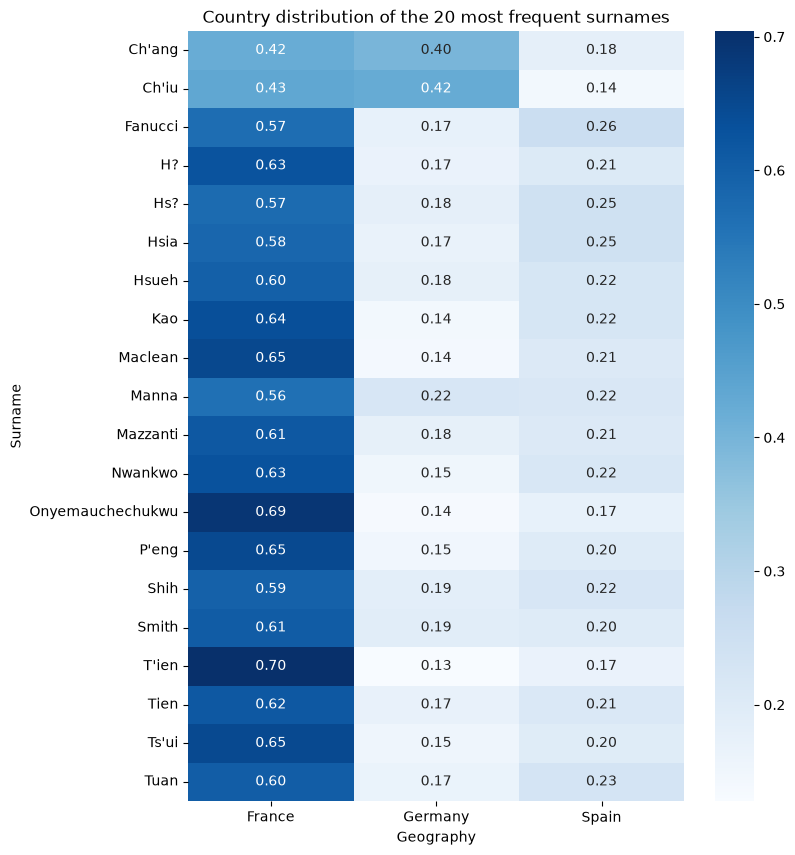

In [17]:
top_surnames = train["Surname"].value_counts().head(20).index
top = train[train["Surname"].isin(top_surnames)]
ct = pd.crosstab(top["Surname"], top["Geography"], normalize="index")

plt.figure(figsize=(8, 10))
sns.heatmap(ct, annot=True, fmt=".2f", cmap="Blues")
plt.title("Country distribution of the 20 most frequent surnames")
plt.show()

### χ² test of independence: Surname × Geography

- **H0:** `Surname` is independent of `Geography`. **α = 5%**, set before the test.
- **Condition:** at least 5 *expected* counts per cell. The smallest expected cell is Germany: n × 0.21 ≥ 5, so n ≥ 24. Surnames with fewer than 24 rows are excluded (filter on the total per surname, not on the per-country counts, to avoid biasing the test).

In [18]:
cross_tab = pd.crosstab(train["Surname"], train["Geography"])
cross_tab_frequent = cross_tab[cross_tab.sum(axis=1) >= 24]

result = chi2_contingency(cross_tab_frequent)
print("surnames kept:", len(cross_tab_frequent))
print("customers covered:", cross_tab_frequent.values.sum())
print("p-value:", result.pvalue)
print("min expected count:", result.expected_freq.min())

# Strength of the link (out of course): Cramér's V, between 0 (no link) and 1 (perfect link)
n = cross_tab_frequent.values.sum()
k = min(cross_tab_frequent.shape)
cramers_v = np.sqrt(result.statistic / (n * (k - 1)))
print("Cramér's V:", round(cramers_v, 3))

surnames kept: 778
customers covered: 128520
p-value: 0.0
min expected count: 5.049859943977591
Cramér's V: 0.19


**Conclusion**
- Condition met: minimum expected count = 5.05 ≥ 5.
- p < 0.001 < α: **H0 is rejected**. Among the 778 surnames with at least 24 rows (128,520 customers), surnames are not independent of country. This does not prove H1. Since the data was generated (section 4), the result means that the generator partially preserved the surname–country links of the original data.
- With 128,520 customers, even a small deviation gives a tiny p-value: the p-value shows that a link exists, not how strong it is. Strength : **Cramér's V ≈ 0.19**, a weak-to-moderate link (benchmarks for 3 categories: 0.07 weak, 0.21 moderate, 0.35 strong). Part of it is noise: with this many surnames, V would already be about 0.08 under H0. This is consistent with the heatmap: most surnames are close to the overall split, a few deviate clearly.
- This is consistent with surnames being generated partly at random and partly preserving links with other columns (the generator details are not documented).

**Decision:** `Surname` is not used as a feature, because it has no business meaning, it could act as a proxy for ethnic origin (ethical risk), and it has encoding issues. The test result is not the reason for this decision.